# 05. Fine-tuning EfficientNetB0

## Cel eksperymentu

Celem etapu jest zbadanie wpływu częściowego odmrożenia wag pretrenowanego modelu EfficientNetB0 na skuteczność klasyfikacji zmian skórnych ze zbioru HAM10000.

W poprzednim etapie wytrenowano głowicę klasyfikacyjną przy całkowicie zamrożonym ekstraktorze cech EfficientNetB0.
Najlepszy wariant A0, bez augmentacji danych, uzyskał F1-macro = 0.61 na zbiorze walidacyjnym.

W niniejszym etapie zostanie zbadany wpływ:
- zakresu odmrożonych bloków backbone'u,
- wartości learning rate podczas fine-tuningu.

Eksperymenty rozpoczynają się od tego samego checkpointu A0. Na tym etapie nie stosuje się augmentacji ani ważenia klas,
aby ograniczyć liczbę jednocześnie zmienianych czynników.

Główne kryterium oceny: walidacyjne F1-macro.
Dodatkowo analizowane będą: accuracy, balanced accuracy,
val_loss oraz precision (?) i recall poszczególnych klas (?).

## ***1. Konfiguracja środowiska***

In [69]:
import sys
from pathlib import Path

import tensorflow as tf
from tensorflow.keras import layers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
    balanced_accuracy_score
)

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.image_pipeline import create_dataset
from src.utils import build_confusion_matrix, history_plot

In [2]:
print(f"Wersja tensorflow: {tf.__version__}")
print(f"Liczba wykrytych GPU: {len(tf.config.list_physical_devices('GPU'))}")
print(f"Zidentyfikowana karta graficzna: {tf.config.list_physical_devices('GPU')[0]}")

Wersja tensorflow: 2.21.0
Liczba wykrytych GPU: 1
Zidentyfikowana karta graficzna: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


W0000 00:00:1795028764.387677   20774 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


### 1.1. Zmienne globalne

In [3]:
IMG_SIZE=(224,224)
BATCH_SIZE=32
SEED = 42
EPOCHS = 50

tf.keras.utils.set_random_seed(SEED)

label_encoder = joblib.load("../dataset/label_encoder.joblib")
class_names = label_encoder.classes_

BASELINE_PATH = Path("../models/best_baseline_a0.keras")
RESULTS_DIR = Path("../models")

assert BASELINE_PATH.is_file(), (
    f"Nie znaleziono checkpointu: {BASELINE_PATH}\n"
)

## 2. Przygotowanie danych

Do eksperymentów wykorzystano ten sam podział danych, który zastosowano podczas trenowania modelu bazowego.
Zachowanie identycznych podzbiorów treningowego i walidacyjnego umożliwia porównanie wyników fine-tuningu z modelem referencyjnym A0.
Pipeline przetwarzania obrazów pozostaje bez zmian. Etykiety są przekazywane w postaci One-Hot Encoding.
Zbiór testowy nie jest wykorzystywany podczas doboru hiperparametrów.

In [4]:
def datasets():
    train = create_dataset(
        train_df,
        training=True,
        BATCH_SIZE=BATCH_SIZE,
        IMG_SIZE=IMG_SIZE
    )
    
    val = create_dataset(
        val_df,
        training=False,
        BATCH_SIZE=BATCH_SIZE,
        IMG_SIZE=IMG_SIZE
    )
    return train, val

In [5]:
train_df = pd.read_csv("../dataset/train_processed.csv")
val_df = pd.read_csv("../dataset/val_processed.csv")

train, val = datasets()

print(f"Train: {len(train_df)}")
print(f"Validation: {len(val_df)}")

images, labels = next(iter(train))
print("Image batch:", images.shape)
print("Label batch:", labels.shape)

W0000 00:00:1795028764.479944   20774 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1795028764.685481   20774 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13209 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070 Ti, pci bus id: 0000:01:00.0, compute capability: 12.0a


Train: 6409
Validation: 1602
Image batch: (32, 224, 224, 3)
Label batch: (32, 7)


## 3. Wczytanie wytrenowanego baseline'u

### 3.1. Wczytanie checkpointu

In [59]:
model = tf.keras.models.load_model(
    BASELINE_PATH,
    compile=False
)

model.summary()

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [7]:
backbone = model.get_layer("efficientnetb0")

print("Liczba warstw backbone'u:", len(backbone.layers))
print("Backbone trainable:", backbone.trainable)

Liczba warstw backbone'u: 238
Backbone trainable: False


In [8]:
print("Struktura backbone'u:")
for layer in backbone.layers:
    print(
        f"{layer.name:35} "
        f"{layer.__class__.__name__:25} "
        f"trainable={layer.trainable}"
    )

Struktura backbone'u:
input_layer                         InputLayer                trainable=True
rescaling                           Rescaling                 trainable=False
normalization                       Normalization             trainable=False
rescaling_1                         Rescaling                 trainable=False
stem_conv_pad                       ZeroPadding2D             trainable=False
stem_conv                           Conv2D                    trainable=False
stem_bn                             BatchNormalization        trainable=False
stem_activation                     Activation                trainable=False
block1a_dwconv                      DepthwiseConv2D           trainable=False
block1a_bn                          BatchNormalization        trainable=False
block1a_activation                  Activation                trainable=False
block1a_se_squeeze                  GlobalAveragePooling2D    trainable=False
block1a_se_reshape                  Reshape

Backbone modelu EfficientNet-B0 składa się z:
- warstw preprocessingu danych wejściowych
- bloku "STEM" - pierwszej sieci konwolucyjnej
- 7 bloków MOBV (Mobile Inverted Bottleneck Convolution) wykorzystujących mechanizm odwróconego wąskiego gardła
- końcowej sieci konwolucyjnej "top"

W celu zachowania spójnej i interpretowalnej konfiguracji fine-tuningu zdecydowano się na odmrażanie kolejnych grup bloków EfficientNetB0, zamiast  wyboru pojedynczych warstw.

## 4. Przygotowanie fine-tuningu

Przebadane zostaną dwa warianty:
- FT1-2: odmrożenie ostatniego bloku MOBV (block7) + bloku top (top_*)
- FT3-4: Poszerzenie warunków z FT1 o odmrożenie szóstego bloku MOBV.

Wariant FT1-2 dostraja tylko końcowe cechy wysokiego poziomu, natomiast FT3-4 pozwala na większą adaptację backbone'u do obrazów dermatoskopowych.
W obu przypadkach bloki STEM oraz 1-5 MOBV pozostaną zamrożone.

Na każdym z tych wariantów zostaną zbadane po dwie wartości learning_rate.

### 4.1. Funkcja odmrażająca

In [27]:
def unfreeze(backbone, from_block=7):
    """
    Odmraża wybrane końcowe bloki EfficientNetB0.
    
    from_block=7: block7 + top
    from_block=6: block6 + block7 + top

    BatchNormalization pozostaje zamrożone.
    """
    if from_block > 7 or from_block < 1:
        raise ValueError("Dozwolone wartości: liczby całkowite od 1 do 7")

    backbone.trainable = True

    for layer in backbone.layers:
        is_selected = (
            layer.name.startswith(
                tuple(
                    f"block{i}"
                    for i in range(from_block, 8)
                )
            )
            or layer.name.startswith("top_")
        )

        layer.trainable = (
            is_selected
            and not isinstance(
                layer, layers.BatchNormalization
            )
        )

    trainable_layers = [
        layer.name
        for layer in backbone.layers
        if layer.trainable
    ]

    print("Liczba odmrożonych warstw:",
          len(trainable_layers))

    print("Odmrożone warstwy:")
    print(trainable_layers)

    return backbone

### 4.2. Funkcja do eksperymentów

In [10]:
def prepare_finetuning(from_block, learning_rate):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = tf.keras.models.load_model(
        BASELINE_PATH,
        compile=False
    )

    backbone = model.get_layer("efficientnetb0")

    unfreeze(backbone, from_block=from_block)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss=tf.keras.losses.CategoricalCrossentropy(),
        metrics=[
            tf.keras.metrics.CategoricalAccuracy(
                name="accuracy"
            ),
            tf.keras.metrics.F1Score(
                average="macro",
                name="f1_macro"
            )
        ]
    )

    return model

## 5. Plan eksperymentów

W celu określenia wpływu zakresu odmrożenia warstw
oraz wartości learning rate zaprojektowano cztery
eksperymenty fine-tuningu.

Każdy eksperyment:
- rozpoczyna się od checkpointu modelu A0,
- wykorzystuje identyczny podział danych*,
- nie stosuje augmentacji ani class weights,
- korzysta z optymalizatora Adam,
- monitoruje F1-macro na zbiorze walidacyjnym.

Hipoteza:
Dostrojenie końcowych bloków EfficientNetB0 do
obrazów dermatoskopowych pozwoli zwiększyć skuteczność
rozróżniania poszczególnych klas zmian skórnych
względem zamrożonego modelu bazowego.

*$*$* - ze względu na ustawienie `reshuffle_each_iteration=True` przy tworzeniu datasetów, na początku każdego eksperymentu są tworzone nowe obiekty klasy `Dataset` z tym samym ziarnem losowości. Ma to na celu zapewnienie jak najbardziej zbliżonych warunków dla każdego z badanych modeli.

In [11]:
EXPERIMENTS = {
    "FT1": {"from_block": 7, "lr": 1e-5},
    "FT2": {"from_block": 7, "lr": 3e-5},
    "FT3": {"from_block": 6, "lr": 1e-5},
    "FT4": {"from_block": 6, "lr": 3e-5},
}

pd.DataFrame(EXPERIMENTS).T

,from_block,lr
FT1,7.0,0.00001
FT2,7.0,0.00003
FT3,6.0,0.00001
FT4,6.0,0.00003


### 5.1. Funkcja przeprowadzająca konfiguracje przed eksperymentem

In [28]:
def experiment_config(EXPERIMENT_ID):

    config = EXPERIMENTS[EXPERIMENT_ID]

    model= prepare_finetuning(
        from_block=config["from_block"],
        learning_rate=config["lr"]
    )
    
    model.summary()
    initial_metrics = model.evaluate(val, return_dict=True)
    
    checkpoint_path = (
        RESULTS_DIR / f"{EXPERIMENT_ID}_best.keras"
    )
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_f1_macro",
            mode="max",
            save_best_only=True,
        ),
    
        tf.keras.callbacks.EarlyStopping(
            monitor="val_f1_macro",
            mode="max",
            patience=10,
            min_delta=0.005,
            restore_best_weights=True,
        )
    ]

    return model, callbacks, initial_metrics, checkpoint_path

## 6. Eksperyment FT1

### 6.1. Konfiguracja eksperymentu

In [13]:
EXPERIMENT_ID="FT1"
model_FT1, callbacks, initial_metrics_FT1, checkpoint_path_FT1 = experiment_config(EXPERIMENT_ID)

print(f"Startowa wartość metryk: {initial_metrics_FT1}")

Liczba odmrożonych warstw: 12
Odmrożone warstwy:
['block7a_expand_conv', 'block7a_expand_activation', 'block7a_dwconv', 'block7a_activation', 'block7a_se_squeeze', 'block7a_se_reshape', 'block7a_se_reduce', 'block7a_se_expand', 'block7a_se_excite', 'block7a_project_conv', 'top_conv', 'top_activation']


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 1,130,551 (4.31 MB)

 Non-trainable params: 2,927,987 (11.17 MB)

... (2 outputs left out)

I0000 00:00:1795028784.460710   20936 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


49/51 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7946 - f1_macro: 0.5996 - loss: 0.5776

E0000 00:00:1795028786.143747   20935 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795028786.960436   20935 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795028788.239982   20935 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


51/51 ━━━━━━━━━━━━━━━━━━━━ 19s 124ms/step - accuracy: 0.7890 - f1_macro: 0.6154 - loss: 0.5965
Startowa wartość metryk: {'accuracy': 0.7890137434005737, 'f1_macro': 0.615447461605072, 'loss': 0.5965262055397034}


### 6.2. Trening

In [14]:
train, val = datasets()

In [15]:
history_FT1 = model_FT1.fit(
    train,
    validation_data=val,
    epochs=EPOCHS,
    callbacks=callbacks
)

/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/50


I0000 00:00:1795028796.423659   20937 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_25942__.260


200/201 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8144 - f1_macro: 0.7071 - loss: 0.5001

I0000 00:00:1795028807.842552   20935 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_25942__.260
E0000 00:00:1795028809.020408   20935 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795028810.302467   20935 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795028810.892896   20935 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


201/201 ━━━━━━━━━━━━━━━━━━━━ 27s 77ms/step - accuracy: 0.8145 - f1_macro: 0.7070 - loss: 0.4996 - val_accuracy: 0.7878 - val_f1_macro: 0.6097 - val_loss: 0.5925
Epoch 2/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.8229 - f1_macro: 0.7095 - loss: 0.4875 - val_accuracy: 0.7865 - val_f1_macro: 0.6089 - val_loss: 0.6042
Epoch 3/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.8224 - f1_macro: 0.7161 - loss: 0.4884 - val_accuracy: 0.7859 - val_f1_macro: 0.6129 - val_loss: 0.5914
Epoch 4/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.8249 - f1_macro: 0.7219 - loss: 0.4713 - val_accuracy: 0.7890 - val_f1_macro: 0.6166 - val_loss: 0.5873
Epoch 5/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.8310 - f1_macro: 0.7244 - loss: 0.4557 - val_accuracy: 0.7865 - val_f1_macro: 0.6110 - val_loss: 0.5933
Epoch 6/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.8345 - f1_macro: 0.7328 - loss: 0.4568 - val_accuracy: 0.7871 - val_f1_macro: 0.6161 - v

### 6.3. Ewaluacja modelu

In [16]:
best_model_FT1 = tf.keras.models.load_model(
    checkpoint_path_FT1
)

val_metrics = best_model_FT1.evaluate(
    val,
    return_dict=True
)

print(val_metrics)

51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 64ms/step - accuracy: 0.8021 - f1_macro: 0.6520 - loss: 0.5585
{'accuracy': 0.8021223545074463, 'f1_macro': 0.6519957780838013, 'loss': 0.5585336089134216}


In [17]:
history_df = pd.DataFrame(history_FT1.history)

history_df.to_csv(
    RESULTS_DIR / f"{EXPERIMENT_ID}_history.csv",
    index=False
)

## 7. Eksperyment FT2

### 7.1. Konfiguracja eksperymentu

In [18]:
EXPERIMENT_ID="FT2"
model_FT2, callbacks, initial_metrics_FT2, checkpoint_path_FT2 = experiment_config("FT2")

print(f"Startowa wartość metryk: {initial_metrics_FT2}")

Liczba odmrożonych warstw: 12
Odmrożone warstwy:
['block7a_expand_conv', 'block7a_expand_activation', 'block7a_dwconv', 'block7a_activation', 'block7a_se_squeeze', 'block7a_se_reshape', 'block7a_se_reduce', 'block7a_se_expand', 'block7a_se_excite', 'block7a_project_conv', 'top_conv', 'top_activation']


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 1,130,551 (4.31 MB)

 Non-trainable params: 2,927,987 (11.17 MB)

51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 63ms/step - accuracy: 0.7890 - f1_macro: 0.6154 - loss: 0.5965
Startowa wartość metryk: {'accuracy': 0.7890137434005737, 'f1_macro': 0.615447461605072, 'loss': 0.5965262055397034}


### 7.2. Trening

In [19]:
train, val = datasets()

In [20]:
history_FT2 = model_FT2.fit(
    train,
    validation_data=val,
    epochs=EPOCHS,
    callbacks=callbacks
)

/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/50


I0000 00:00:1795028965.988586   20937 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_107840__.260


197/201 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8150 - f1_macro: 0.7053 - loss: 0.5037

I0000 00:00:1795028975.456540   20935 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_107840__.260


201/201 ━━━━━━━━━━━━━━━━━━━━ 22s 56ms/step - accuracy: 0.8153 - f1_macro: 0.7073 - loss: 0.5032 - val_accuracy: 0.7878 - val_f1_macro: 0.6278 - val_loss: 0.5857
Epoch 2/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.8243 - f1_macro: 0.7111 - loss: 0.4774 - val_accuracy: 0.7834 - val_f1_macro: 0.6081 - val_loss: 0.6062
Epoch 3/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.8281 - f1_macro: 0.7246 - loss: 0.4635 - val_accuracy: 0.7890 - val_f1_macro: 0.6263 - val_loss: 0.5840
Epoch 4/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.8419 - f1_macro: 0.7511 - loss: 0.4356 - val_accuracy: 0.7871 - val_f1_macro: 0.6298 - val_loss: 0.5767
Epoch 5/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8477 - f1_macro: 0.7572 - loss: 0.4127 - val_accuracy: 0.7946 - val_f1_macro: 0.6302 - val_loss: 0.5877
Epoch 6/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8510 - f1_macro: 0.7609 - loss: 0.4053 - val_accuracy: 0.7984 - val_f1_macro: 0.6410 - v

### 7.3. Ewaluacja modelu

In [21]:
best_model_FT2 = tf.keras.models.load_model(
    checkpoint_path_FT2
)

val_metrics = best_model_FT2.evaluate(
    val,
    return_dict=True
)

print(val_metrics)

51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 61ms/step - accuracy: 0.8165 - f1_macro: 0.6783 - loss: 0.5703
{'accuracy': 0.8164793848991394, 'f1_macro': 0.6782635450363159, 'loss': 0.5703467130661011}


In [22]:
history_df = pd.DataFrame(history_FT2.history)

history_df.to_csv(
    RESULTS_DIR / f"{EXPERIMENT_ID}_history.csv",
    index=False
)

## 8. Eksperyment FT3

### 8.1. Konfiguracja eksperymentu

In [29]:
EXPERIMENT_ID="FT3"
model_FT3, callbacks, initial_metrics_FT3, checkpoint_path_FT3 = experiment_config("FT3")

print(f"Startowa wartość metryk: {initial_metrics_FT3}")

Liczba odmrożonych warstw: 59
Odmrożone warstwy:
['block6a_expand_conv', 'block6a_expand_activation', 'block6a_dwconv_pad', 'block6a_dwconv', 'block6a_activation', 'block6a_se_squeeze', 'block6a_se_reshape', 'block6a_se_reduce', 'block6a_se_expand', 'block6a_se_excite', 'block6a_project_conv', 'block6b_expand_conv', 'block6b_expand_activation', 'block6b_dwconv', 'block6b_activation', 'block6b_se_squeeze', 'block6b_se_reshape', 'block6b_se_reduce', 'block6b_se_expand', 'block6b_se_excite', 'block6b_project_conv', 'block6b_drop', 'block6b_add', 'block6c_expand_conv', 'block6c_expand_activation', 'block6c_dwconv', 'block6c_activation', 'block6c_se_squeeze', 'block6c_se_reshape', 'block6c_se_reduce', 'block6c_se_expand', 'block6c_se_excite', 'block6c_project_conv', 'block6c_drop', 'block6c_add', 'block6d_expand_conv', 'block6d_expand_activation', 'block6d_dwconv', 'block6d_activation', 'block6d_se_squeeze', 'block6d_se_reshape', 'block6d_se_reduce', 'block6d_se_expand', 'block6d_se_excite'

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 3,138,851 (11.97 MB)

 Non-trainable params: 919,687 (3.51 MB)

51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 60ms/step - accuracy: 0.7890 - f1_macro: 0.6154 - loss: 0.5965
Startowa wartość metryk: {'accuracy': 0.7890137434005737, 'f1_macro': 0.615447461605072, 'loss': 0.5965262055397034}


### 8.2. Trening

In [30]:
train, val = datasets()

In [31]:
history_FT3 = model_FT3.fit(
    train,
    validation_data=val,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/50


/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795029367.762101   20936 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_206581__.260
E0000 00:00:1795029368.424492   20936 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


199/201 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8174 - f1_macro: 0.7123 - loss: 0.4950

I0000 00:00:1795029379.547926   20938 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_206581__.260
E0000 00:00:1795029380.168308   20938 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


201/201 ━━━━━━━━━━━━━━━━━━━━ 26s 62ms/step - accuracy: 0.8176 - f1_macro: 0.7130 - loss: 0.4948 - val_accuracy: 0.7928 - val_f1_macro: 0.6375 - val_loss: 0.5809
Epoch 2/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.8315 - f1_macro: 0.7270 - loss: 0.4665 - val_accuracy: 0.7953 - val_f1_macro: 0.6350 - val_loss: 0.6010
Epoch 3/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8332 - f1_macro: 0.7384 - loss: 0.4523 - val_accuracy: 0.7940 - val_f1_macro: 0.6390 - val_loss: 0.5732
Epoch 4/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.8380 - f1_macro: 0.7443 - loss: 0.4311 - val_accuracy: 0.7946 - val_f1_macro: 0.6485 - val_loss: 0.5631
Epoch 5/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8485 - f1_macro: 0.7634 - loss: 0.4047 - val_accuracy: 0.8009 - val_f1_macro: 0.6494 - val_loss: 0.5764
Epoch 6/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8530 - f1_macro: 0.7647 - loss: 0.3979 - val_accuracy: 0.8065 - val_f1_macro: 0.6582 - v

### 8.3. Ewaluacja modelu

In [32]:
best_model_FT3 = tf.keras.models.load_model(
    checkpoint_path_FT3
)

val_metrics = best_model_FT3.evaluate(
    val,
    return_dict=True
)

print(val_metrics)

51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 70ms/step - accuracy: 0.8171 - f1_macro: 0.6819 - loss: 0.5711
{'accuracy': 0.8171036243438721, 'f1_macro': 0.6819295883178711, 'loss': 0.5710580945014954}


In [33]:
history_df = pd.DataFrame(history_FT3.history)

history_df.to_csv(
    RESULTS_DIR / f"{EXPERIMENT_ID}_history.csv",
    index=False
)

## 9. Eksperyment FT4

### 9.1. Konfiguracja eksperymentu

In [34]:
EXPERIMENT_ID="FT4"
model_FT4, callbacks, initial_metrics_FT4, checkpoint_path_FT4 = experiment_config("FT4")

print(f"Startowa wartość metryk: {initial_metrics_FT4}")

Liczba odmrożonych warstw: 59
Odmrożone warstwy:
['block6a_expand_conv', 'block6a_expand_activation', 'block6a_dwconv_pad', 'block6a_dwconv', 'block6a_activation', 'block6a_se_squeeze', 'block6a_se_reshape', 'block6a_se_reduce', 'block6a_se_expand', 'block6a_se_excite', 'block6a_project_conv', 'block6b_expand_conv', 'block6b_expand_activation', 'block6b_dwconv', 'block6b_activation', 'block6b_se_squeeze', 'block6b_se_reshape', 'block6b_se_reduce', 'block6b_se_expand', 'block6b_se_excite', 'block6b_project_conv', 'block6b_drop', 'block6b_add', 'block6c_expand_conv', 'block6c_expand_activation', 'block6c_dwconv', 'block6c_activation', 'block6c_se_squeeze', 'block6c_se_reshape', 'block6c_se_reduce', 'block6c_se_expand', 'block6c_se_excite', 'block6c_project_conv', 'block6c_drop', 'block6c_add', 'block6d_expand_conv', 'block6d_expand_activation', 'block6d_dwconv', 'block6d_activation', 'block6d_se_squeeze', 'block6d_se_reshape', 'block6d_se_reduce', 'block6d_se_expand', 'block6d_se_excite'

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 3,138,851 (11.97 MB)

 Non-trainable params: 919,687 (3.51 MB)

51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 65ms/step - accuracy: 0.7890 - f1_macro: 0.6154 - loss: 0.5965
Startowa wartość metryk: {'accuracy': 0.7890137434005737, 'f1_macro': 0.615447461605072, 'loss': 0.5965262055397034}


### 9.2. Trening

In [35]:
train, val = datasets()

In [36]:
history_FT4 = model_FT4.fit(
    train,
    validation_data=val,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/50


/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795029578.934359   20935 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_305307__.260


198/201 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8130 - f1_macro: 0.7020 - loss: 0.5002

I0000 00:00:1795029589.230539   20934 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_305307__.260


201/201 ━━━━━━━━━━━━━━━━━━━━ 25s 58ms/step - accuracy: 0.8132 - f1_macro: 0.7037 - loss: 0.4996 - val_accuracy: 0.7928 - val_f1_macro: 0.6385 - val_loss: 0.5704
Epoch 2/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8369 - f1_macro: 0.7414 - loss: 0.4422 - val_accuracy: 0.7996 - val_f1_macro: 0.6567 - val_loss: 0.5649
Epoch 3/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.8482 - f1_macro: 0.7705 - loss: 0.4051 - val_accuracy: 0.8027 - val_f1_macro: 0.6522 - val_loss: 0.5648
Epoch 4/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.8632 - f1_macro: 0.7860 - loss: 0.3694 - val_accuracy: 0.8052 - val_f1_macro: 0.6531 - val_loss: 0.5533
Epoch 5/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - accuracy: 0.8822 - f1_macro: 0.8172 - loss: 0.3264 - val_accuracy: 0.8102 - val_f1_macro: 0.6673 - val_loss: 0.5933
Epoch 6/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - accuracy: 0.8870 - f1_macro: 0.8257 - loss: 0.3091 - val_accuracy: 0.8109 - val_f1_macro: 0.6734 - v

### 9.3. Ewaluacja modelu

In [37]:
best_model_FT4 = tf.keras.models.load_model(
    checkpoint_path_FT4
)

val_metrics = best_model_FT4.evaluate(
    val,
    return_dict=True
)

print(val_metrics)

51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 64ms/step - accuracy: 0.8090 - f1_macro: 0.6750 - loss: 0.6122
{'accuracy': 0.8089887499809265, 'f1_macro': 0.6749643683433533, 'loss': 0.6122267842292786}


In [38]:
history_df = pd.DataFrame(history_FT4.history)

history_df.to_csv(
    RESULTS_DIR / f"{EXPERIMENT_ID}_history.csv",
    index=False
)

## 10. Wyniki eksperymentów fine-tuningu

### 10.1. Porównanie metryk końcowych modeli

In [54]:
models_dict = {
    "Model FT1": best_model_FT1,
    "Model FT2": best_model_FT2,
    "Model FT3": best_model_FT3,
    "Model FT4": best_model_FT4,
}

Metrics_table = pd.DataFrame({
    name: {metric: float(val) for metric, val in model.get_metrics_result().items()}
    for name, model in models_dict.items()
})

Metrics_table

,Model FT1,Model FT2,Model FT3,Model FT4
loss,0.558534,0.570347,0.571058,0.612227
accuracy,0.802122,0.816479,0.817104,0.808989
f1_macro,0.651996,0.678264,0.681930,0.674964


### 10.2. Wykresy nauki

#### Model FT1

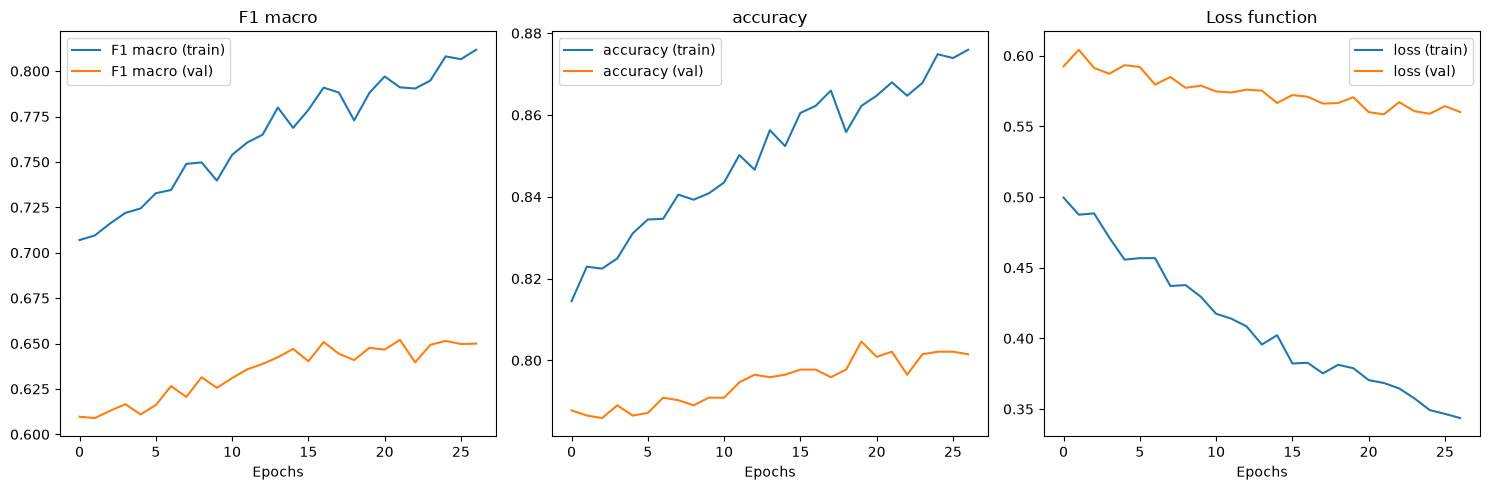

In [55]:
history_plot(history_FT1)

#### Model FT2

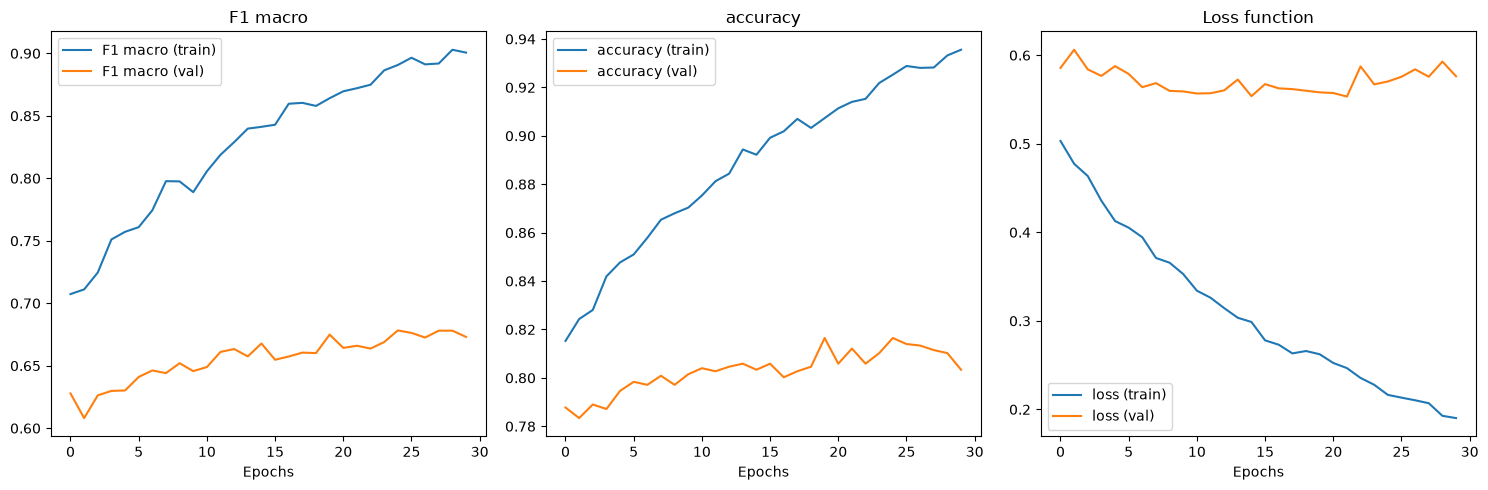

In [56]:
history_plot(history_FT2)

#### Model FT3

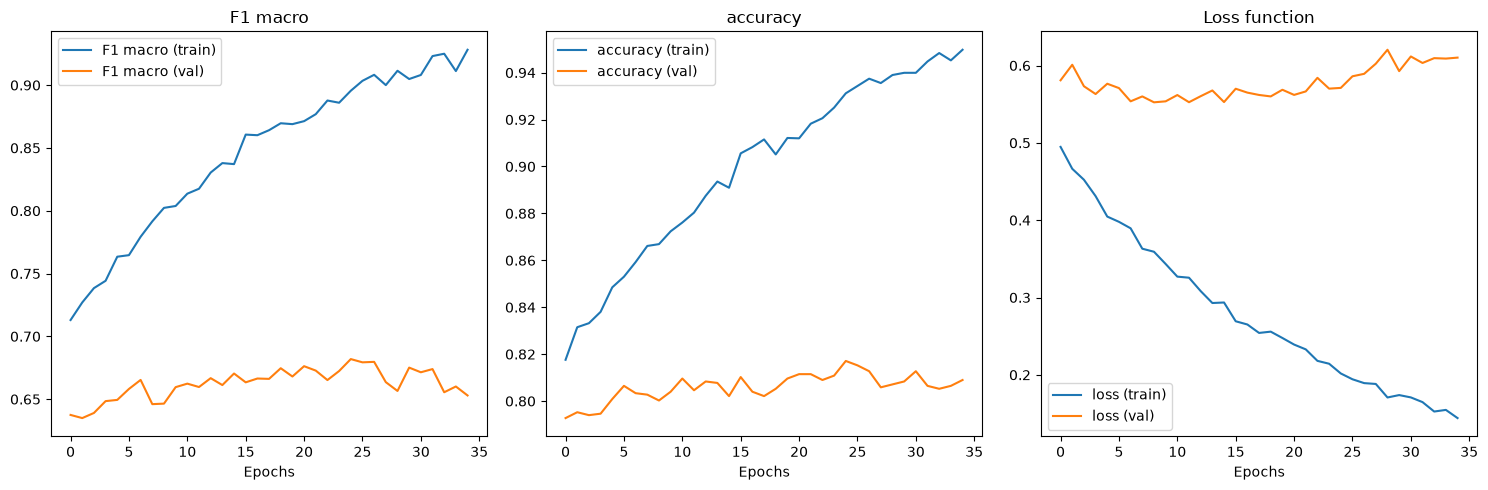

In [57]:
history_plot(history_FT3)

#### Model FT4

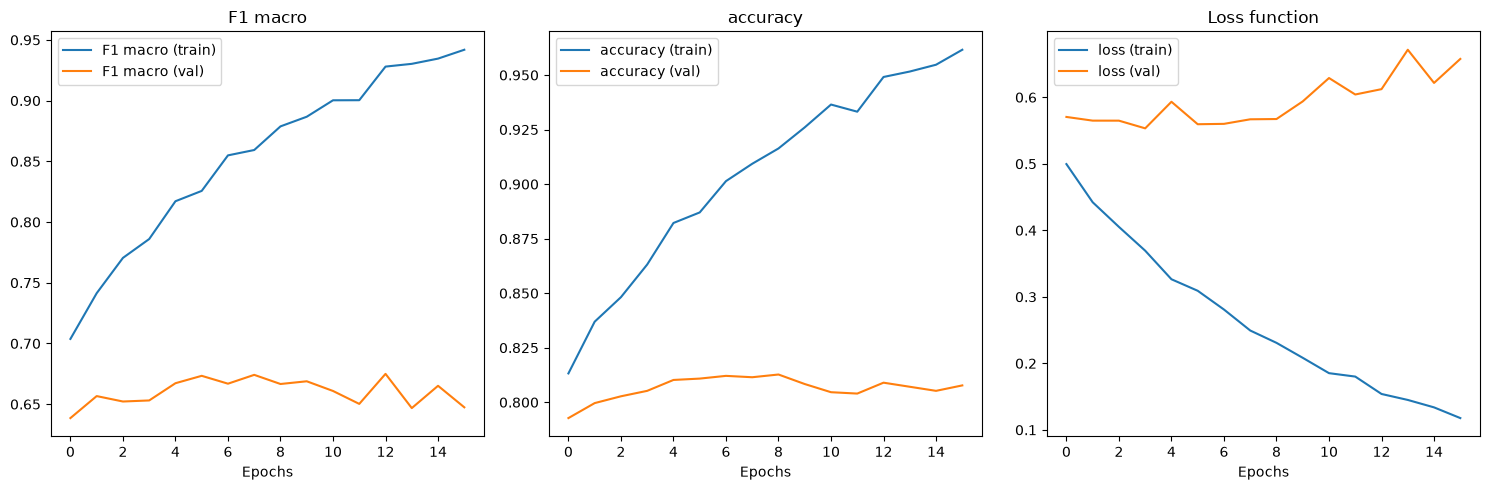

In [58]:
history_plot(history_FT4)

### 10.3. Macierze pomyłek najlepszych modeli - FT3 i FT2

51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 90ms/step


Text(0.5, 1.0, 'Macierz pomyłek FT2')

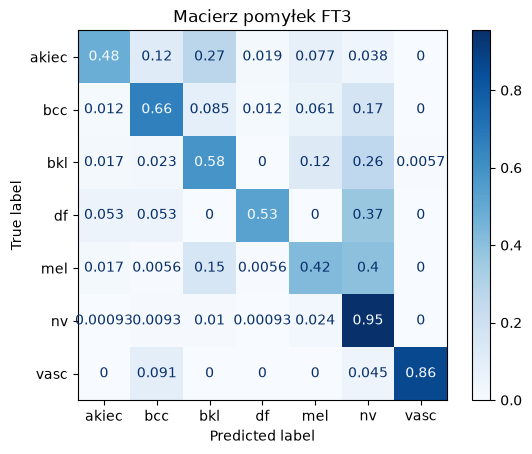

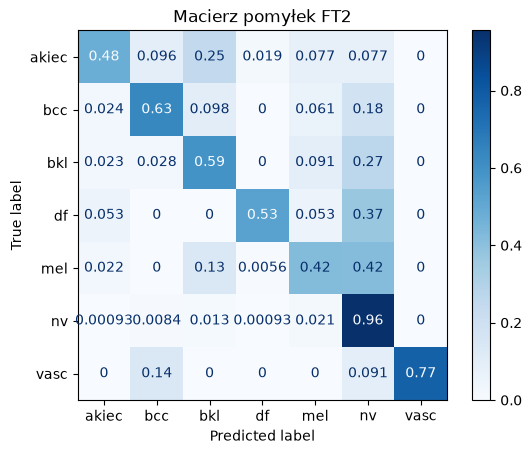

In [71]:
cmatrix3, display3 = build_confusion_matrix(best_model_FT3, val, class_names)
cmatrix2, display2 = build_confusion_matrix(best_model_FT2, val, class_names)

display3.plot(cmap='Blues')
plt.title("Macierz pomyłek FT3")

display2.plot(cmap='Blues')
plt.title("Macierz pomyłek FT2")

### 10.4. Macierz różnic między najlepszym modelem a baseline A0

51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step


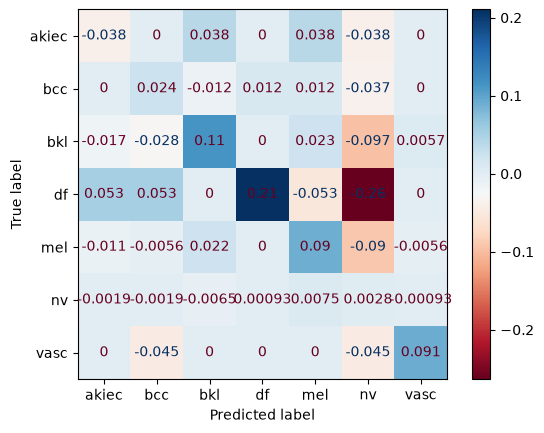

In [74]:
cmatrix_a0, _ = build_confusion_matrix(model, val, class_names)

cmatrix_diff = (cmatrix3 - cmatrix_a0)

display_diff = ConfusionMatrixDisplay(cmatrix_diff, display_labels=class_names)

display_diff.plot(cmap='RdBu')

## 11. Analiza wyników, podsumowanie i wnioski.*

Przeprowadzone eksperymenty wykazały, że częściowe odmrożenie wag pretrenowanego modelu EfficientNetB0 pozwala poprawić skuteczność klasyfikacji zmian skórnych ze zbioru HAM10000 względem modelu z całkowicie zamrożonym ekstraktorem cech.

Wszystkie cztery konfiguracje fine-tuningu osiągnęły wyższe wartości walidacyjnego F1-macro od modelu bazowego A0 (0,6154). Najlepszy wynik uzyskano w eksperymencie FT3, w którym odmrożono bloki 6–7 oraz końcowe warstwy top_*, wykorzystując learning rate równy 1e-5. Model ten osiągnął $F1-macro = 0,6819$ oraz $accuracy = 0,8171$ na zbiorze walidacyjnym. Oznacza to poprawę F1-macro o prawie 7 punktów procentowych względem baseline'u.

Zbliżony wynik uzyskał wariant FT2 (F1-macro = 0,6783), wykorzystujący mniejszy zakres odmrożenia i learning rate 3e-5. Niewielka różnica między FT2 i FT3 nie pozwala jednak jednoznacznie określić, która konfiguracja charakteryzuje się lepszą generalizacją. Wymagałoby to powtórzenia eksperymentów z różnymi ziarnami losowości.

Wyniki sugerują, że zwiększenie liczby trenowalnych parametrów może być korzystne, ale wymaga odpowiedniego dostosowania tempa uczenia. Zarówno FT2 i FT4 z learning rate równym 3e-5 posiadały zbliżony wynik F1 makro, mimo szerszego zakresu odmrożenia.

Analiza przebiegu treningu wskazuje także na powszechne występowanie zjawiska przeuczenia, szczególnie w modelach o większej liczbie trenowalnych parametrów i wyższej wartości learning rate.

Porównanie macierzy pomyłek modelu FT3 z modelem bazowym A0 wykazało, że poprawa wyników nie rozkłada się równomiernie pomiędzy klasami. Największy wzrost *sensitivity* zaobserwowano dla klasy df — z około 0,32 do 0,53. Wyraźną poprawę uzyskano również dla bkl (z około 0,47 do 0,58), mel (z około 0,33 do 0,42) oraz vasc (z około 0,77 do 0,86). Jednocześnie dla klasy akiec zaobserwowano niewielkie pogorszenie recall. Wynik ten wskazuje, że dostrajanie ekstraktora cech nie poprawia jednakowo zdolności rozróżniania wszystkich klas.

Analiza potwierdza więc, że częściowy fine-tuning ogranicza niektóre błędy klasyfikacji, ale nie eliminuje problemu rozpoznawania wizualnie podobnych zmian skórnych. Dominująca liczebnie klasa nv nadal pozostaje częstym kierunkiem błędnych predykcji innych klas.

Przeprowadzone eksperymenty potwierdzają zasadność zastosowania częściowego fine-tuningu EfficientNetB0 do klasyfikacji obrazów dermatoskopowych. Dostosowanie końcowych warstw ekstraktora cech pozwoliło uzyskać lepsze wyniki niż trenowanie wyłącznie głowicy klasyfikacyjnej.

Najwyższą walidacyjną wartość F1-macro osiągnął wariant FT3, jednak zbliżone wyniki FT2 wskazują, że zwiększanie zakresu odmrażania nie musi być konieczne do osiągnięcia porównywalnej skuteczności.

W kolejnych etapach zaplanowano zbadanie wpływu augmentacji obrazów na generalizację modelu, ze szczególnym uwzględnieniem obrotów i odbić lustrzanych. Następnie przewidziano eksperymenty z ważeniem klas, mające na celu ograniczenie wpływu nierównomiernego rozkładu diagnoz. Dodatkowo zostanie rozważone zastosowanie harmonogramu learning rate oraz ocena stabilności wybranych konfiguracji przy różnych ziarnach losowości.

Do kolejnych eksperymentów wybrano wariant FT3 jako konfigurację referencyjną, z zachowaniem FT2 jako alternatywę.

$*$ - Wszystkie przedstawione wyniki dotyczą zbioru walidacyjnego. Ocena skuteczności wybranego rozwiązania na niezależnym zbiorze testowym zostanie przeprowadzona po zakończeniu procesu doboru konfiguracji modelu.